In [263]:
import numpy as np
import matplotlib.pyplot as plt
import japanize_matplotlib
import random

from thinkbayes import _DictWrapper
import bisect
import thinkbayes

class Pmf(_DictWrapper):

    def __add__(self, other):
        pmf = Pmf()
        for v1, p1 in self.Items():
            for v2, p2 in other.Items():
                pmf.Incr(v1+v2, p1*p2)
        return pmf

  


    def Normalize(self, fraction=1.0):
        if self.log:
            raise ValueError("Pmf is under a log transforms")
        total = self.Total()
        if total == 0.0:
            raise ValueError("total probability is zero")
            return total
        factor = float(fraction)/total
        for x in self.d:
            self.d[x] *=factor
        return total

    def Random(self):
        if len(self.d) == 0:
            raise ValueError('Pmf contains no values.')

        target = random.random()
        total = 0.0
        for x, p in self.d.items():
            total += p
            if total >= target:
                return x

        assert False

    def Max(self, k):
        cdf = self.MakeCdf()
        cdf.ps = [p**k for p in cdf.ps]
        return cdf

    def MakeCdf(self, name=None):
        return MakeCdfFromPmf(self, name=name)
    

class Suite(Pmf):
    def Update(self, data):
        for hypo in list(self.Values()):
            like = self.Likelihood(data, hypo)
            self.Mult(hypo, like)
        return self.Normalize()
    
    def MakeCdf(self, name=None):
            return MakeCdfFromPmf(self, name=name)

    def UpdateSet(self, dataset):
        for data in dataset:
            for hypo in self.Values():
                like = self.Likelihood(data, hypo)
                self.Mult(hypo, like)
        return self.Normalize()

def MakeCdfFromPmf(pmf, name=None):
    if name == None:
        name = pmf.name
    return MakeCdfFromItems(pmf.Items(), name)

def MakeCdfFromItems(items, name=''):
    runsum = 0
    xs = []
    cs = []

    for value, count in sorted(items):
        runsum += count
        xs.append(value)
        cs.append(runsum)

    total = float(runsum)
    ps = [c/total for c in cs]
    cdf = Cdf(xs, ps, name)
    return cdf

def MakePmfFromList(t, name=""):
    hist = MakeHistFromList(t)
    d = hist.GetDict()
    pmf = Pmf(d, name)
    pmf.Normalize()
    return pmf

def MakeHistFromList(t, name=''):
    hist = Hist(name=name)
    [hist.Incr(x) for x in t]
    return hist

def MakePmfFromCdf(cdf, name=None):
    if name is None:
        name = cdf.name

    pmf = Pmf(name=name)
    prev = 0.0
    for val, prob in cdf.Items():
        pmf.Incr(val, prob - prev)
        prev = prob
    return pmf


def SampleSum(dists, n):
    pmf = MakePmfFromList(RandomSum(dists) for i in range(n))
    return pmf

def SampleMax(dists, n):
    pmf = MakePmfFromList(RandomMax(dists) for i in range(n))
    return pmf


def RandomSum(dists):
    total = sum(dist.Random() for dist in dists)
    return total

def RandomMax(dists):
    total = max(dist.Random() for dist in dists)
    return total


class Cdf(object):
    def __init__(self, xs=None, ps=None, name=''):
        self.xs = [] if xs is None else xs
        self.ps = [] if ps is None else ps
        self.name = name

    def Value(self,p):
        if p < 0 or p > 1:
            raise ValueError('Probability p must be in range [0, 1]')

        if p == 0: return self.xs[0]
        if p == 1: return self.xs[-1]
        index = bisect.bisect(self.ps, p)
        if p == self.ps[index - 1]:
            return self.xs[index - 1]
        else:
            return self.xs[index]

    def Max(self, k):
        cdf = self.Copy()
        cdf.ps = [p**k for p in cdf.ps]
        return cdf

    def Items(self):
        return zip(self.xs, self.ps)
        
class Hist(_DictWrapper):

    pass

class Die(Pmf):
    def __init__(self, sides, name=''):
        Pmf.__init__(self, name=name)
        for x in range(1, sides+1):
            self.Set(x,1)
        self.Normalize()



In [264]:
class Die(Pmf):
    def __init__(self, sides):
        Pmf.__init__(self)
        for x in np.arange(1, sides+1):
            self.Set(x, 1)
        self.Normalize()

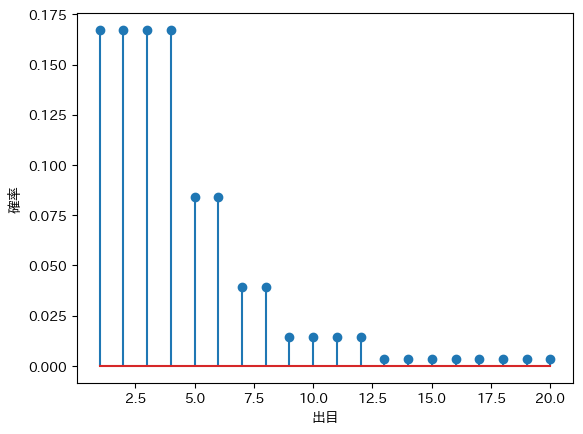

In [274]:
pmf_dice = thinkbayes.Pmf()
pmf_dice.Set(Die(4), 5)
pmf_dice.Set(Die(6), 4)
pmf_dice.Set(Die(8), 3)
pmf_dice.Set(Die(12), 2)
pmf_dice.Set(Die(20), 1)
pmf_dice.Normalize()

mix = thinkbayes.Pmf()
for die, weight in pmf_dice.Items():
    for outcome, prob in die.Items():
        mix.Incr(outcome, weight*prob)

mix = thinkbayes.MakeMixture(pmf_dice)


xs, ps = zip(*sorted(mix.Items()))

plt.stem(xs, ps)
plt.xlabel("出目")
plt.ylabel("確率")
plt.show()

In [265]:
d6 = Die(6)

dice = [d6]*3

three = SampleSum(dice, 1000)

dists = [three]*6

maxima = SampleMax(dists,1000)

maxima.Items()






dict_items([(14, 0.202), (16, 0.151), (17, 0.107), (13, 0.14400000000000002), (15, 0.202), (11, 0.048), (10, 0.02), (12, 0.084), (18, 0.041), (9, 0.001)])

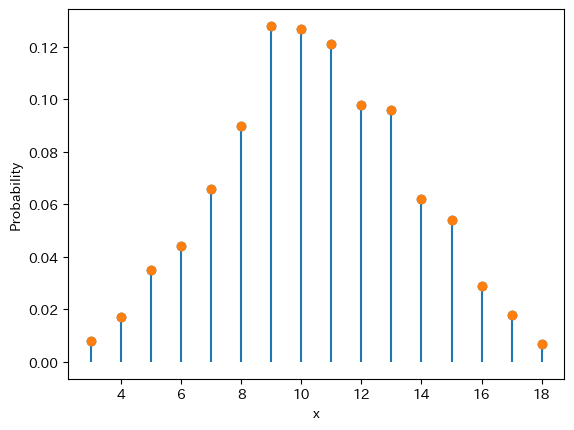

In [266]:
xs0, ps0 = zip(*sorted(three.Items()))
plt.stem(xs0, ps0, basefmt=" ")
plt.plot(xs0, ps0, "o")

plt.xlabel("x")
plt.ylabel("Probability")
plt.show()

In [267]:
print(maxima.__dict__)

{'name': '', 'd': {14: 0.202, 16: 0.151, 17: 0.107, 13: 0.14400000000000002, 15: 0.202, 11: 0.048, 10: 0.02, 12: 0.084, 18: 0.041, 9: 0.001}, 'log': False}


In [268]:
xs = range(3, 19)
ps = [maxima.d.get(x,0) for x in xs]

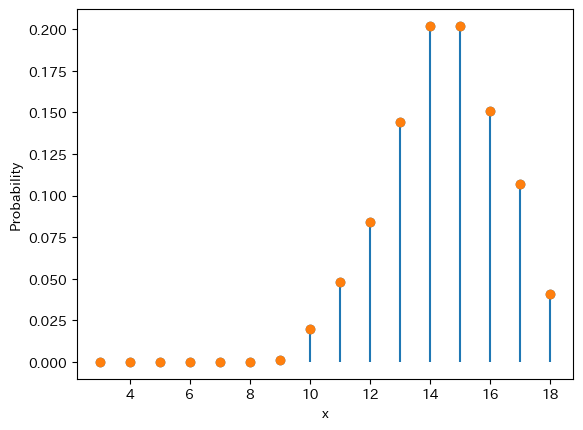

In [269]:
plt.stem(xs, ps, basefmt=" ")
plt.plot(xs, ps, "o")

plt.xlabel("x")
plt.ylabel("Probability")
plt.show()

In [270]:
def PmfMax(pmf1, pmf2):
    res = Pmf()
    for v1, p1 in pmf1.Items():
        for v2, p2 in pmf2.Items():
            res.Incr(max(v1,v2), p1*p2)
    return res

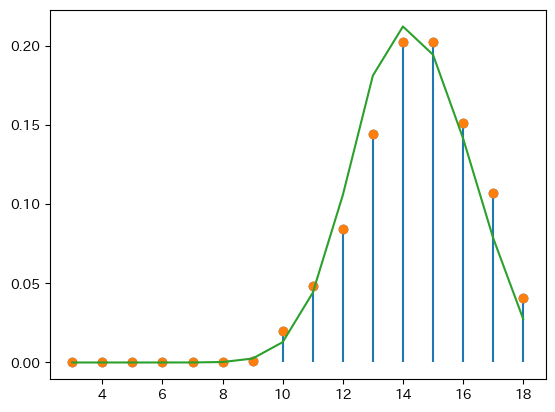

In [271]:
three_exact = d6 + d6 + d6
three_exact.name ="exact"


best_attr2 = PmfMax(three_exact, three_exact)
best_attr4 = PmfMax(best_attr2, best_attr2)
best_attr6 = PmfMax(best_attr4, best_attr2)

best_attr6.Items()

xs2, ps2 = zip(*best_attr6.Items())

plt.stem(xs, ps, basefmt=" ")
plt.plot(xs, ps, "o")
plt.plot(xs2, ps2)


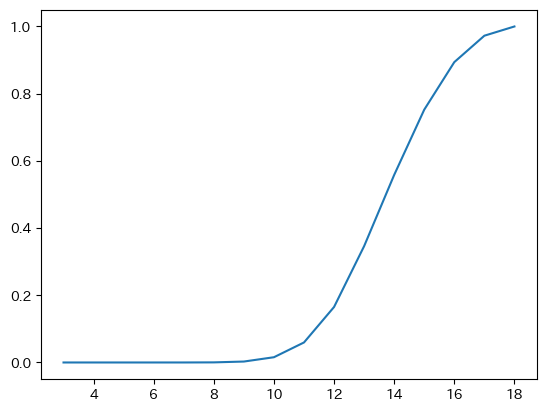

In [272]:
best_attr_cdf = three_exact.Max(6)
best_attr_cdf.name = ""

xs3, ps3 = zip(*best_attr_cdf.Items())

plt.plot(xs3, ps3)

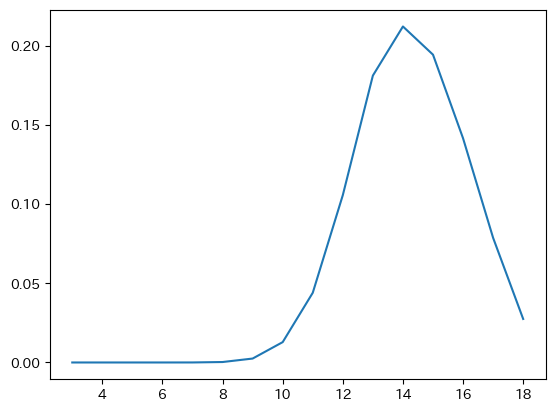

In [273]:
best_attr_pmf = MakePmfFromCdf(best_attr_cdf)

best_attr_pmf.Items()

xs2 = range(3, 19)
ps2 = [best_attr_pmf.d.get(x,0) for x in xs]

plt.plot(xs2, ps2)